# ДЗ 1. Рекомендации товаров

Сосунов Дмитрий Анатольевич

Взял отзывы на товары Amazon Prime Pantry. По прошлым отзывам нужно предложить пользователю десять товаров, которые он ещё не оценивал. Релевантным считаю товар с будущей оценкой 4 или 5. Отзыв здесь говорит о предпочтении, но сам по себе не подтверждает покупку.

## 1. Данные

Использую [Amazon Review Data (2018)](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/index.html), категорию Prime Pantry. Взял готовый 5-core целиком: 137 788 отзывов, у каждого пользователя и товара изначально не меньше пяти отзывов.

Основные поля: `reviewerID` — пользователь, `asin` — товар, `overall` — оценка от 1 до 5, `unixReviewTime` — дата. В отдельном файле есть названия и бренды товаров.

Открыть ноутбук в VS Code или Jupyter, выбрать ядро Python 3.12 и выполнить все ячейки по порядку. Первая ячейка установит зависимости. Расчёт идёт на CPU.

При загрузке данных ноутбук сам скачает [отзывы](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Prime_Pantry_5.json.gz) и [метаданные](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Prime_Pantry.json.gz) в `data/raw/`. Если файлы уже есть, повторно скачивать их не нужно.

In [1]:
%pip install -q -r requirements.txt


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import gzip
import json
from pathlib import Path
from urllib.request import urlretrieve
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import sparse
from IPython.display import display
from threadpoolctl import threadpool_limits

from models.item_knn import ItemKNN
from models.ials import IALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.custom_ials import CustomIALS

seed = 2026
np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(1)
# Много маленьких систем в ALS быстрее считать в одном потоке.
thread_limit = threadpool_limits(limits=1)
pd.set_option('display.precision', 5)

In [3]:
folder = Path('data/raw')
folder.mkdir(parents=True, exist_ok=True)
base = 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/'
files = {
    'Prime_Pantry_5.json.gz': base + 'categoryFilesSmall/Prime_Pantry_5.json.gz',
    'meta_Prime_Pantry.json.gz': base + 'metaFiles2/meta_Prime_Pantry.json.gz',
}
for name, url in files.items():
    path = folder / name
    if not path.exists():
        print('Скачиваю', name)
        temporary = path.with_suffix('.part')
        urlretrieve(url, temporary)
        temporary.replace(path)

In [4]:
rows = []
with gzip.open(folder / 'Prime_Pantry_5.json.gz', 'rt') as f:
    for line in f:
        row = json.loads(line)
        rows.append([row.get(k) for k in ['reviewerID', 'asin', 'overall', 'unixReviewTime']])
raw = pd.DataFrame(rows, columns=['user_id', 'item_id', 'rating', 'timestamp'])
print('Отзывы:', len(raw), '; пользователи:', raw.user_id.nunique(), '; товары:', raw.item_id.nunique())
display(raw.head())
display(raw.isna().sum().to_frame('Пропуски'))
print('Полностью одинаковых строк:', raw.duplicated().sum())

Отзывы: 137788 ; пользователи: 14180 ; товары: 4970


,user_id,item_id,rating,timestamp
0,A31Y9ELLA1JUB0,B0000DIWNI,4.0,1443052800
1,A2FYW9VZ0AMXKY,B0000DIWNI,5.0,1435017600
2,A1NE43T0OM6NNX,B0000DIWNI,5.0,1434153600
3,AHTCPGK2CNPKU,B0000DIWNI,4.0,1433289600
4,A25SIBTMVXLB59,B0000DIWNI,5.0,1429488000


,Пропуски
user_id,0
item_id,0
rating,0
timestamp,0


Полностью одинаковых строк: 6442


## 2. Подготовка и EDA

Пропусков в основных полях и оценок вне диапазона 1–5 нет. Повторяющиеся пары пользователь–товар удаляю: оставляю первый отзыв по времени, при совпадении дат — первую строку. Так поздняя оценка не заменит ту, которая была известна раньше.

После удаления 6 674 повторных строк осталось 131 114 отзывов, 14 180 пользователей и 4 970 товаров. Дополнительную подвыборку не делаю. Повторные покупки здесь не рассматриваю.

In [5]:
events = raw.dropna().copy()
valid = events.rating.between(1, 5) & (events.timestamp > 0)
print('Некорректных строк:', (~valid).sum())
events = events[valid].sort_values('timestamp', kind='stable')
print('Повторных пар:', events.duplicated(['user_id', 'item_id']).sum())
events = events.drop_duplicates(['user_id', 'item_id'], keep='first').copy()
events['u'], users = pd.factorize(events.user_id, sort=True)
events['i'], items = pd.factorize(events.item_id, sort=True)
events['timestamp'] = events.timestamp.astype(np.int64)
events = events.reset_index(drop=True)
shape = len(users), len(items)
assert 100_000 <= len(events) <= 2_000_000 and min(shape) >= 1000
print('После очистки:', len(events), 'отзывов,', shape[0], 'пользователей,', shape[1], 'товаров')

Некорректных строк: 0
Повторных пар: 6674
После очистки: 131114 отзывов, 14180 пользователей, 4970 товаров


,user_activity,item_popularity
count,14180.00000,4970.00000
mean,9.24640,26.38109
std,8.33539,38.52326
min,1.00000,1.00000
25%,5.00000,8.00000
50%,7.00000,13.00000
75%,10.00000,28.00000
max,183.00000,575.00000


Период: 2006-04-09 00:00:00+00:00 — 2018-10-04 00:00:00+00:00
Заполнено 0.186% матрицы, разреженность 99.814%
Пользователей / товаров с менее чем 5 отзывами после очистки: 1063 17


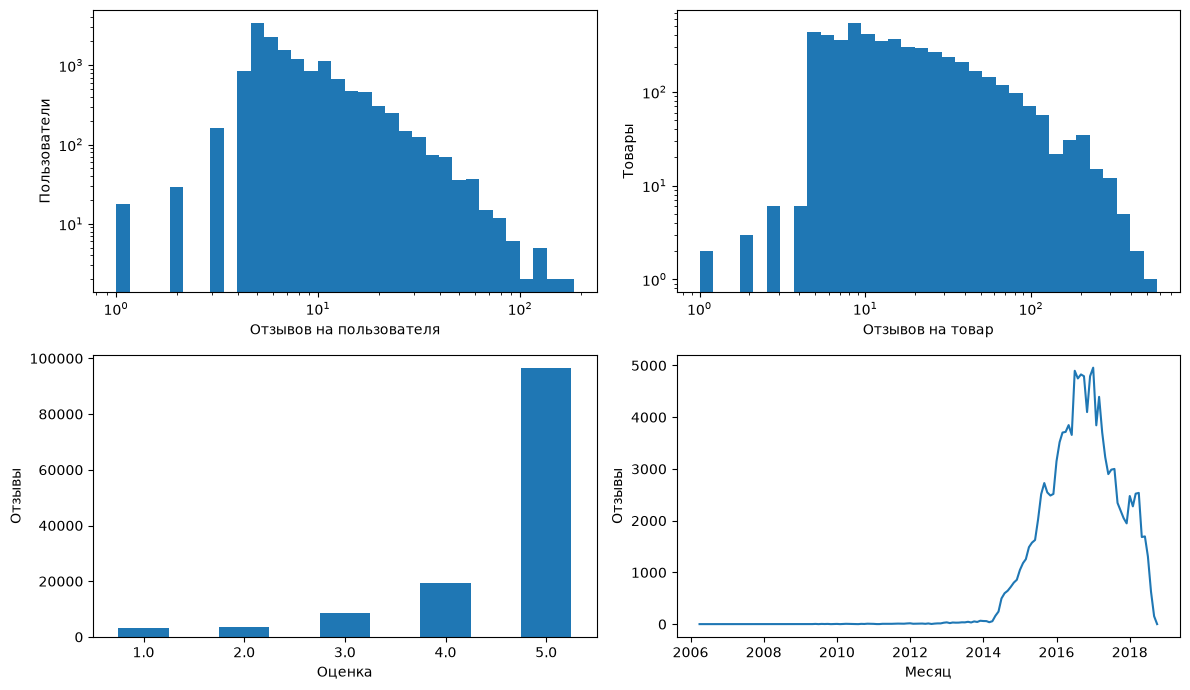

In [6]:
user_activity = events.groupby('u').size()
item_activity = events.groupby('i').size()
display(pd.DataFrame({'user_activity': user_activity.describe(),
                      'item_popularity': item_activity.describe()}))
dates = pd.to_datetime(events.timestamp, unit='s', utc=True)
print('Период:', dates.min(), '—', dates.max())
density = len(events) / (shape[0] * shape[1])
print(f'Заполнено {density:.3%} матрицы, разреженность {1-density:.3%}')
print('Пользователей / товаров с менее чем 5 отзывами после очистки:',
      int((user_activity < 5).sum()), int((item_activity < 5).sum()))
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].hist(user_activity, bins=np.geomspace(1, user_activity.max()+1, 35))
axes[0, 0].set(xscale='log', yscale='log', xlabel='Отзывов на пользователя', ylabel='Пользователи')
axes[0, 1].hist(item_activity, bins=np.geomspace(1, item_activity.max()+1, 35))
axes[0, 1].set(xscale='log', yscale='log', xlabel='Отзывов на товар', ylabel='Товары')
events.rating.value_counts().sort_index().plot.bar(ax=axes[1, 0], rot=0)
axes[1, 0].set(xlabel='Оценка', ylabel='Отзывы')
monthly = events.assign(month=dates.dt.strftime('%Y-%m')).groupby('month').size()
axes[1, 1].plot(pd.to_datetime(monthly.index), monthly)
axes[1, 1].set(xlabel='Месяц', ylabel='Отзывы')
fig.tight_layout()
plt.show()

In [7]:
by_item = {}
with gzip.open(folder / 'meta_Prime_Pantry.json.gz', 'rt') as f:
    for line in f:
        row = json.loads(line)
        if row['asin'] not in by_item:
            by_item[row['asin']] = {k: row.get(k) for k in ['title', 'brand', 'category']}
metadata = pd.DataFrame([by_item.get(item, {}) for item in items])
metadata['item_id'] = items
metadata_counts = pd.Series({
    'Товаров': len(metadata),
    'Есть название': metadata.title.fillna('').str.strip().ne('').sum(),
    'Есть бренд': metadata.brand.fillna('').str.strip().ne('').sum(),
    'Есть категория': metadata.category.map(lambda x: isinstance(x, list) and len(x) > 0).sum(),
    'Разных брендов': metadata.brand.fillna('').replace('', np.nan).nunique(),
})
display(metadata_counts.to_frame('Количество'))
display(metadata[['title', 'brand']].head())

,Количество
Товаров,4970
Есть название,4968
Есть бренд,4968
Есть категория,0
Разных брендов,1102


,title,brand
0,"Saran Premium Plastic Wrap, 100 Sq Ft",Saran
1,"Chicken of the Sea, Solid White Albacore Tuna ...",Chicken of the Sea
2,QKR STNDRD OATMEAL - QUICK 18OZ,Quaker
3,"Manwich Original Sloppy Joe Sauce, 15 Oz.",Hunt's
4,"Progresso Soup, Vegetable Classics, Lentil Sou...",Progresso


In [8]:
metadata.brand.fillna('(нет)').replace('', '(нет)').value_counts().head(10).to_frame('Товаров')

,Товаров
brand,
Quaker,109
Barilla,64
Neutrogena,48
Method,48
McCormick,45
Campbell's,45
Planters,43
Blue Diamond Almonds,37
Betty Crocker,36


У пользователя в медиане 7 отзывов, у товара — 13; максимумы — 183 и 575. Матрица заполнена всего на 0.186%. Большинство оценок высокие, а активность пользователей и популярность товаров сильно различаются.

Названия и бренды нашлись у 4 968 товаров, категории пустые. Оставляю эти поля для описания данных и примеров выдачи. Для FM возьму дату и статистики прошлых отзывов: для них можно проверить, что информация была известна в момент рекомендации.

5-core уже отобран по всей истории, поэтому в нём больше активных пользователей и товаров. После очистки заново 5-core не строю, чтобы не усиливать этот отбор.

## 3. Разбиение и метрики

Делю отзывы по времени примерно на 70% / 15% / 15%. Общие для всех пользователей границы — 3 апреля 2017 и 25 октября 2017; события одного UTC-дня остаются вместе. Параметры выбираю на validation, затем переобучаю модели на train + validation и сравниваю на test.

На начало периода строю одну выдачу из всех товаров обучающей истории. Уже оценённые пользователем товары исключаю, включая низкие оценки. Для оценки оставляю пользователей с положительной историей и хотя бы одним новым релевантным товаром в доступном каталоге. Новых пользователей и новые товары не оцениваю. Эти правила одинаковы для всех моделей; при равных score первым идёт меньший индекс товара.

Основная метрика — **NDCG@10**: важно, чтобы понравившиеся товары были ближе к началу списка. Дополнительно считаю **Recall@10**, долю найденных релевантных товаров. Если $L_u^{10}$ — выдача, а $R_u$ — доступные товары с оценкой 4–5 в отложенной части, то

$$Recall@10(u)=\frac{|L_u^{10}\cap R_u|}{|R_u|},\qquad
NDCG@10(u)=\frac{\sum_{j=1}^{10}\mathbf1[L_{uj}\in R_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)}.$$

Усредняю обе метрики по пользователям. Для сравнения разнообразия выдачи также посчитаю число разных рекомендованных товаров.

In [9]:
def temporal_split(events):
    # Границы округляем до UTC-дня, чтобы не разделять события одного дня.
    day = 86400
    t1 = int(np.quantile(events.timestamp, .70) // day * day)
    t2 = int(np.quantile(events.timestamp, .85) // day * day)
    train = events[events.timestamp < t1].copy()
    validation = events[(events.timestamp >= t1) & (events.timestamp < t2)].copy()
    test = events[events.timestamp >= t2].copy()
    assert train.timestamp.max() < validation.timestamp.min()
    assert validation.timestamp.max() < test.timestamp.min()
    return train, validation, test, t1, t2

train, validation, test, t1, t2 = temporal_split(events)
split_table = pd.DataFrame([
    {'split': name, 'events': len(frame), 'users': frame.u.nunique(), 'items': frame.i.nunique(),
     'from': pd.to_datetime(frame.timestamp.min(), unit='s', utc=True),
     'to': pd.to_datetime(frame.timestamp.max(), unit='s', utc=True)}
    for name, frame in [('train', train), ('validation', validation), ('test', test)]
])
display(split_table)

,split,events,users,items,from,to
0,train,91711,11155,4906,2006-04-09 00:00:00+00:00,2017-04-02 00:00:00+00:00
1,validation,19711,4306,3732,2017-04-03 00:00:00+00:00,2017-10-24 00:00:00+00:00
2,test,19692,3883,3497,2017-10-25 00:00:00+00:00,2018-10-04 00:00:00+00:00


In [10]:
def matrices(events, shape):
    location = (events.u.to_numpy(), events.i.to_numpy())
    observed = sparse.csr_matrix((np.ones(len(events)), location), shape=shape)
    target = sparse.csr_matrix(((events.rating >= 4).to_numpy(dtype=float), location), shape=shape)
    positive = target.copy()
    positive.eliminate_zeros()
    return observed, positive, target


def protocol(history, holdout, shape):
    seen, positive, _ = matrices(history, shape)
    candidates = np.asarray(seen.sum(axis=0)).ravel() > 0
    warm_user = np.asarray(positive.sum(axis=1)).ravel() > 0
    relevant = holdout[holdout.rating >= 4]
    warm_item = candidates[relevant.i.to_numpy()]
    warm_users = warm_user[relevant.u.to_numpy()]
    eligible = relevant[warm_item & warm_users]
    truth = eligible.groupby('u', sort=True).i.agg(lambda x: set(x)).to_dict()
    users = np.array(sorted(truth), dtype=np.int64)
    for user in users:
        assert not truth[user].intersection(seen[user].indices)
    return {'users': users, 'truth': truth, 'seen': seen, 'candidates': candidates,
            'coverage': len(eligible) / len(relevant)}

In [11]:
def topk(scores, seen, candidates, k=10):
    scores = np.array(scores, dtype=np.float64, copy=True)
    if not np.isfinite(scores).all():
        raise ValueError("Model produced a nonfinite score")
    scores[:, ~candidates] = -np.inf
    row, col = seen.nonzero()
    scores[row, col] = -np.inf
    if np.any(np.isfinite(scores).sum(axis=1) < k):
        raise ValueError("Fewer than k eligible items")
    # При равных score сохраняем порядок индексов товаров.
    return np.argsort(-scores, axis=1, kind="stable")[:, :k]


def user_metrics(recommended, relevant):
    k = len(recommended)
    hits = np.array([item in relevant for item in recommended])
    discount = 1 / np.log2(np.arange(2, k + 2))
    ideal = discount[:min(k, len(relevant))].sum()
    return {'ndcg@10': float(hits @ discount / ideal),
            'recall@10': float(hits.sum() / len(relevant))}

In [12]:
def evaluate(model, setup, batch_size=128):
    rows, recommended_items = [], set()
    users = setup['users']
    for start in range(0, len(users), batch_size):
        batch = users[start:start + batch_size]
        recommendations = topk(model.score(batch), setup['seen'][batch], setup['candidates'])
        for user, top in zip(batch, recommendations):
            assert len(set(top)) == 10
            assert setup['candidates'][top].all()
            assert not set(top).intersection(setup['seen'][user].indices)
            rows.append({'user': int(user), **user_metrics(top, setup['truth'][user])})
            recommended_items.update(top)
    per_user = pd.DataFrame(rows).set_index('user')
    summary = per_user.mean().to_dict()
    summary['unique_items'] = len(recommended_items)
    return summary

validation_setup = protocol(train, validation, shape)
print('Пользователей для validation:', len(validation_setup['users']))

Пользователей для validation: 2286


## 4. Модели

Код моделей лежит в `models/`. Использую NumPy и SciPy, а для FM — PyTorch с autograd и Adam. Для сравнения возьму также самые популярные товары.

### ItemKNN

$X_{ui}=1[r_{ui}\ge4]$. Считаю cosine между товарами с поправкой на число общих пользователей $n_{ij}$:

$$s_{ij}=\frac{X_{:i}^TX_{:j}}{\|X_{:i}\|\|X_{:j}\|}\frac{n_{ij}}{n_{ij}+\beta}.$$

При $\beta=0$ это обычный cosine. В каждом столбце оставляю $k$ соседей, диагональ зануляю. Оценки товаров: $XS$.

### iALS

Для наблюдавшихся пар $p_{ui}=1[r_{ui}\ge4]$, для неизвестных — 0. Confidence у любого отзыва выше, чем у неизвестной пары:

$$c_{ui}=1+\alpha\mathbf1[(u,i)\in\Omega],\qquad
L=\sum_{ui}c_{ui}(p_{ui}-a_u^Tb_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2).$$

По очереди решаю линейные системы для факторов пользователей и товаров. Предсказание — $a_u^Tb_i$. Нули низких оценок храню в sparse-матрице явно, иначе они потеряют повышенный confidence.

### EASE

$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\qquad \operatorname{diag}(W)=0.$$

Для $P=(X^TX+\lambda I)^{-1}$ веса $W_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$, диагональ — 0. Предсказание — $XW$. Обратную матрицу считаю через Cholesky. Для 4 970 товаров веса помещаются в память; на большом каталоге это было бы проблемой.

### FM

В FM добавляю признаки пользователя, товара и даты к их ID. Формула второго порядка:

$$\hat s(x)=w_0+\sum_jw_jx_j+\frac12\sum_f\left[(\sum_jv_{jf}x_j)^2-\sum_jv_{jf}^2x_j^2\right].$$

Вектор состоит из восьми полей:

| Поля | Как считаю и зачем добавил |
|---|---|
| user ID, item ID | предпочтения пользователя и особенности товара |
| month, weekday | one-hot месяца и дня недели, чтобы учесть возможную сезонность |
| user activity | $\log(1+N_u)/5$ по прошлым отзывам, активность пользователя |
| user mean rating | $(\bar r_u-3)/2$, привычный уровень оценок; без истории 0 |
| item popularity | $\log(1+N_i^+)/5$ по прошлым положительным отзывам |
| item age | $\log(1+age_i)/8$, дни с первого наблюдения товара; без истории 0 |

Статистики считаю только по предыдущим дням, делители 5 и 8 фиксированы. При выдаче использую обучающую историю и дату начала периода. Текущий отзыв в собственные признаки не попадает.

Обучаю с logistic loss: оценки 4–5 получают метку 1, оценки 1–3 — 0. На каждый положительный отзыв добавляю два случайных товара без отзыва. Выбираю их из каталога прошлых дней, исключив уже известные и текущие за день отзывы пользователя. Будущие отзывы не использую. Отсутствие отзыва, конечно, не гарантирует отрицательное предпочтение.

Признаки собираю ниже, сама FM находится в `models/fm.py`.

Чтобы проверить пользу признаков, обучаю **FM (IDs only)** на тех же примерах и с теми же параметрами, оставив только ID. Отдельно параметры для этого варианта не подбираю.

In [13]:
class HistoryFeatures:
    def __init__(self, shape):
        self.n_users, self.n_items = shape
        self.user_count = np.zeros(self.n_users)
        self.user_sum = np.zeros(self.n_users)
        self.item_positive = np.zeros(self.n_items)
        self.item_first = np.full(self.n_items, np.inf)
        self.history = [set() for _ in range(self.n_users)]
        self.offset = self.n_users + self.n_items
        self.n_features = self.offset + 12 + 7 + 4

    def update(self, frame):
        u, i = frame.u.to_numpy(), frame.i.to_numpy()
        np.add.at(self.user_count, u, 1)
        np.add.at(self.user_sum, u, frame.rating.to_numpy())
        np.add.at(self.item_positive, i, (frame.rating >= 4).to_numpy().astype(float))
        np.minimum.at(self.item_first, i, frame.timestamp.to_numpy())
        for user, item in zip(u, i):
            self.history[user].add(item)

    def groups(self, users, items, timestamp):
        users, items = np.asarray(users), np.asarray(items)
        base = self.offset + 19
        uid = np.column_stack([users, np.full(len(users), base), np.full(len(users), base + 1)])
        mean = np.divide(self.user_sum[users], self.user_count[users],
                         out=np.full(len(users), 3.), where=self.user_count[users] > 0)
        ux = np.column_stack([np.ones(len(users)), np.log1p(self.user_count[users]) / 5,
                              (mean - 3) / 2])
        iid = np.column_stack([self.n_users + items, np.full(len(items), base + 2),
                               np.full(len(items), base + 3)])
        age = np.maximum(0, (timestamp - self.item_first[items]) / 86400)
        ix = np.column_stack([np.ones(len(items)), np.log1p(self.item_positive[items]) / 5,
                              np.log1p(age) / 8])
        date = datetime.fromtimestamp(float(timestamp), timezone.utc)
        cid = np.array([[self.offset + date.month - 1, self.offset + 12 + date.weekday()]])
        cx = np.ones((1, 2))
        return (uid, ux), (iid, ix), (cid, cx)

    def pairs(self, users, items, timestamp):
        ug, ig, cg = self.groups(users, items, timestamp)
        ids = np.column_stack([ug[0], ig[0], np.repeat(cg[0], len(users), axis=0)])
        values = np.column_stack([ug[1], ig[1], np.repeat(cg[1], len(users), axis=0)])
        return ids.astype(np.int64), values.astype(np.float32)

In [14]:
def training_examples(events, shape, negatives=2, seed=2026):
    rng = np.random.default_rng(seed)
    state = HistoryFeatures(shape)
    ids, values, labels = [], [], []
    for timestamp, day in events.groupby('timestamp', sort=True):
        users, items = day.u.tolist(), day.i.tolist()
        y = (day.rating >= 4).astype(float).tolist()
        available = np.flatnonzero(state.item_first < timestamp)
        today = day.groupby('u').i.agg(set).to_dict()
        if len(available):
            for row in day[day.rating >= 4].itertuples():
                forbidden = state.history[row.u] | today[row.u]
                if len(forbidden) >= len(available) and len(forbidden.intersection(available)) == len(available):
                    continue
                for _ in range(negatives):
                    item = int(rng.choice(available))
                    while item in forbidden:
                        item = int(rng.choice(available))
                    users.append(row.u)
                    items.append(item)
                    y.append(0.)
        day_ids, day_values = state.pairs(users, items, timestamp)
        ids.append(day_ids)
        values.append(day_values)
        labels.extend(y)
        # Отзывы текущего дня пока не добавлены в статистики.
        state.update(day)
    return np.vstack(ids), np.vstack(values), np.asarray(labels, dtype=np.float32), state

### Мой вариант iALS

Обычный таргет склеивает оценки 4 и 5, а оценки от 1 до 3 превращает в ноль. Я попробовал учитывать силу оценки и давность отзыва:

$$q_{ui}(T)=\frac{r_{ui}-3}{2}\left[\rho+(1-\rho)2^{-\frac{T-t_{ui}}{86400h}}\right],\qquad \rho=0.5.$$

Оценки 1–2 дают отрицательное значение, 3 — ноль, 4–5 — положительное. Старые отзывы постепенно теряют вес, но множитель не падает ниже $\rho$. Здесь $h$ — период полураспада в днях, $T$ — начало периода рекомендации, $t_{ui}<T$ — дата обучающего отзыва. Для неизвестных пар $q=0$.

Подставляю $q$ вместо $p$ в iALS, confidence оставляю прежним. Код таргета: `models/custom_ials.py`.

## 5. Подбор параметров

Перебираю 23 варианта. Выбираю максимальный NDCG@10 на validation, при равенстве оставляю первый вариант. Сетку и seed задаю до оценки на test.

Фиксированные настройки: у iALS и моего варианта alpha=20, 12 итераций; у FM lr=0.01, 15 эпох, batch size=4096. У нового таргета floor=0.5. Остальные параметры перебираю ниже.

In [15]:
grids = {
    'ItemKNN': [{'neighbors': k, 'shrinkage': s} for k in [30, 100] for s in [0, 20]],
    'iALS': [{'factors': d, 'reg': r}
             for d in [16, 32] for r in [1., 10.]],
    'EASE': [{'reg': r} for r in [10., 100., 500.]],
    'FM': [{'factors': d, 'reg': r}
           for d in [16, 32] for r in [1e-5, 1e-4]],
}
grids['Custom iALS'] = [{**parameters, 'half_life': h}
                        for parameters in grids['iALS'] for h in [90., 365.]]

In [16]:
def fit_model(name, parameters, events, positive, targets, examples, history, cutoff, metadata=True):
    if name == 'ItemKNN':
        return ItemKNN(**parameters).fit(positive)
    if name == 'iALS':
        return IALS(**parameters, seed=seed).fit(targets)
    if name == 'Custom iALS':
        return CustomIALS(**parameters, seed=seed).fit_events(events, shape, cutoff)
    if name == 'EASE':
        return EASE(**parameters).fit(positive)
    if name == 'FM':
        return FactorizationMachine(history.n_features, metadata=metadata, seed=seed,
                                    **parameters).fit(examples, history, cutoff)

In [17]:
_, positive, targets = matrices(train, shape)
ids, values, labels, history = training_examples(train, shape, seed=seed)
examples = (ids, values, labels)
validation_rows = []
selection = {}

for name, grid in grids.items():
    best = -1
    for parameters in grid:
        model = fit_model(name, parameters, train, positive, targets, examples, history, t1)
        scores = evaluate(model, validation_setup)
        validation_rows.append({'model': name, 'parameters': parameters.copy(), **scores})
        if scores['ndcg@10'] > best:
            best = scores['ndcg@10']
            selection[name] = parameters.copy()
    print(name, '— лучший validation NDCG@10:', round(best, 5))

validation_results = pd.DataFrame(validation_rows)
with pd.option_context('display.max_colwidth', None):
    display(validation_results[['model', 'parameters', 'ndcg@10', 'recall@10']])

ItemKNN — лучший validation NDCG@10: 0.01629


iALS — лучший validation NDCG@10: 0.01762


EASE — лучший validation NDCG@10: 0.01748


FM — лучший validation NDCG@10: 0.02036


Custom iALS — лучший validation NDCG@10: 0.01598


,model,parameters,ndcg@10,recall@10
0,ItemKNN,"{'neighbors': 30, 'shrinkage': 0}",0.00801,0.01034
1,ItemKNN,"{'neighbors': 30, 'shrinkage': 20}",0.01526,0.01909
2,ItemKNN,"{'neighbors': 100, 'shrinkage': 0}",0.00778,0.01029
3,ItemKNN,"{'neighbors': 100, 'shrinkage': 20}",0.01629,0.02137
4,iALS,"{'factors': 16, 'reg': 1.0}",0.01742,0.02391
5,iALS,"{'factors': 16, 'reg': 10.0}",0.01762,0.02461
6,iALS,"{'factors': 32, 'reg': 1.0}",0.01711,0.02440
7,iALS,"{'factors': 32, 'reg': 10.0}",0.01733,0.02337
8,EASE,{'reg': 10.0},0.01481,0.02073
9,EASE,{'reg': 100.0},0.01709,0.02449


## 6. Результаты на test

Переобучаю пять моделей на train + validation с выбранными настройками. Для сравнения добавлю популярные товары и FM без дополнительных признаков. У FM с признаками и без них одинаковые параметры и обучающие примеры.

In [18]:
class Popularity:
    def __init__(self, positive):
        self.counts = np.asarray(positive.sum(axis=0)).ravel()

    def score(self, users):
        return np.broadcast_to(self.counts, (len(users), len(self.counts)))

final_history = pd.concat([train, validation], ignore_index=True)
test_setup = protocol(final_history, test, shape)
_, positive, targets = matrices(final_history, shape)
ids, values, labels, history = training_examples(final_history, shape, seed=seed)
examples = (ids, values, labels)
print('Пользователей для test:', len(test_setup['users']))
print('Доля положительных событий, попавших в оценку:',
      f"{test_setup['coverage']:.2%}")

Пользователей для test: 2280
Доля положительных событий, попавших в оценку: 45.62%


In [19]:
rows = []
recommendations = {}
baseline = Popularity(positive)
rows.append({'model': 'Popularity', 'parameters': {}, **evaluate(baseline, test_setup)})
sample_users = test_setup['users'][:1]

for name in [*selection, 'FM (IDs only)']:
    kind = 'FM' if name == 'FM (IDs only)' else name
    parameters = selection[kind]
    model = fit_model(kind, parameters, final_history, positive, targets, examples, history, t2,
                      metadata=name != 'FM (IDs only)')
    scores = evaluate(model, test_setup)
    rows.append({'model': name, 'parameters': parameters.copy(), **scores})
    recommendations[name] = topk(model.score(sample_users), test_setup['seen'][sample_users],
                          test_setup['candidates'])

results = pd.DataFrame(rows)
display(results[['model', 'ndcg@10', 'recall@10', 'unique_items']])
print('Выбранные параметры:')
display(pd.Series(selection, name='parameters').to_frame())

,model,ndcg@10,recall@10,unique_items
0,Popularity,0.01595,0.02313,16
1,ItemKNN,0.01865,0.02475,3480
2,iALS,0.01881,0.02546,481
3,EASE,0.01900,0.02677,2187
4,FM,0.01857,0.02499,17
5,Custom iALS,0.01630,0.02259,732
6,FM (IDs only),0.01857,0.02468,16


Выбранные параметры:


,parameters
ItemKNN,"{'neighbors': 100, 'shrinkage': 20}"
iALS,"{'factors': 16, 'reg': 10.0}"
EASE,{'reg': 500.0}
FM,"{'factors': 32, 'reg': 0.0001}"
Custom iALS,"{'factors': 32, 'reg': 10.0, 'half_life': 365.0}"


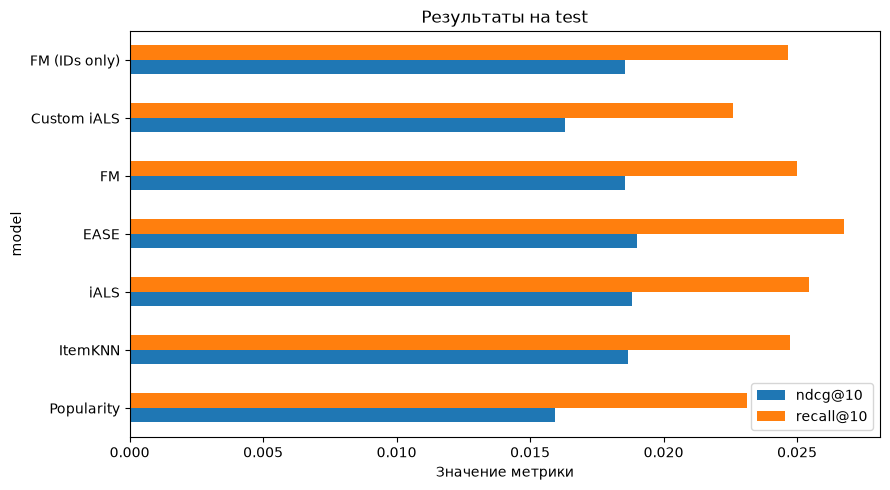

In [20]:
results.set_index('model')[['ndcg@10', 'recall@10']].plot.barh(figsize=(9, 5))
plt.xlabel('Значение метрики')
plt.title('Результаты на test')
plt.tight_layout()
plt.show()

### Пример рекомендаций

Посмотрю выдачу EASE для первого пользователя тестовой группы. Отмечу товары, которые получили оценку 4–5 в test.

In [21]:
for position, user in enumerate(sample_users):
    print('Пользователь', user)
    top = recommendations['EASE'][position]
    sample = metadata.loc[top, ['title', 'brand']].copy()
    sample['Оценка 4–5 в test'] = [item in test_setup['truth'][user] for item in top]
    display(sample.reset_index(names='item'))

Пользователь 3


,item,title,brand,Оценка 4–5 в test
0,265,"Mott's Unsweetened Applesauce, 3.9 Ounce Cup, ...",Mott's,False
1,1389,"Kellogg's Breakfast Cereal, Frosted Mini-Wheat...",Kellogg's,False
2,537,"Pepperidge Farm, Milano, Cookies, Double Dark ...",Pepperidge Farm,False
3,1879,"Honey Maid Graham Crackers, 14.4 Ounce",Honey Maid,False
4,1,"Chicken of the Sea, Solid White Albacore Tuna ...",Chicken of the Sea,False
5,624,"Cinnamon Toast Crunch Breakfast Cereal, 23.6 oz",Cinnamon Toast Crunch,False
6,1452,"Ritz Peanut Butter Cracker Sandwiches, 8 Count...",Ritz,False
7,534,"Pace Chunky Salsa, Medium, 64 oz",Pace,False
8,630,"Nature Valley Granola Bars, Crunchy, Variety P...",Nature Valley,False
9,674,"Lucky Charms Gluten Free Breakfast Cereal, 20....",Lucky Charms,False


## 7. Выводы

Лучший результат у EASE с reg=500: NDCG@10 = 0.01900, Recall@10 = 0.02677. Рядом iALS (0.01881) и ItemKNN (0.01865). Все пять моделей выше popularity по NDCG, но разница небольшая.

Признаки FM почти ничего не дали: NDCG с ними 0.018572, без них 0.018569. По всем пользователям FM рекомендует всего 17 разных товаров, а EASE — 2 187. В этом запуске FM получилась слабо персонализированной.

Мой вариант iALS оказался хуже обычного: NDCG 0.01630 против 0.01881, Recall 0.02259 против 0.02546. У моделей различаются и выбранные параметры, поэтому разницу нельзя объяснить только новым таргетом. Идея учитывать силу оценки и давность здесь улучшения не дала.

В test оцениваются 2 280 пользователей и 45.62% положительных событий. Новых пользователей и товары этот эксперимент не покрывает. Ещё ограничения: готовый 5-core отобран по всей истории, сетка параметров небольшая, а разбиение и seed только одни. По одному запуску нельзя уверенно судить о небольших различиях моделей; дальше стоит проверить их на других временных срезах.